<a href="https://colab.research.google.com/github/bhatprajwal1328-debug/Prajwal-project-1-eda-car-/blob/main/Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [52]:
df=pd.read_csv("/content/car.csv")

In [53]:
# ----  INSPECT ----
print(df.shape)
print(df.columns)
print(df.dtypes)
print(df.head())
print(df.info())

(8128, 13)
Index(['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type',
       'transmission', 'owner', 'mileage', 'engine', 'max_power', 'torque',
       'seats'],
      dtype='object')
name              object
year               int64
selling_price      int64
km_driven          int64
fuel              object
seller_type       object
transmission      object
owner             object
mileage           object
engine            object
max_power         object
torque            object
seats            float64
dtype: object
                           name  year  selling_price  km_driven    fuel  \
0        Maruti Swift Dzire VDI  2014         450000     145500  Diesel   
1  Skoda Rapid 1.5 TDI Ambition  2014         370000     120000  Diesel   
2      Honda City 2017-2020 EXi  2006         158000     140000  Petrol   
3     Hyundai i20 Sportz Diesel  2010         225000     127000  Diesel   
4        Maruti Swift VXI BSIII  2007         130000     120000  Petrol   

  seller

In [54]:
num_cols = ['year', 'selling_price', 'km_driven', 'seats']
cat_cols = ['fuel', 'seller_type', 'transmission', 'owner']
print("Numerical:", num_cols)
print("Categorical:", cat_cols)

Numerical: ['year', 'selling_price', 'km_driven', 'seats']
Categorical: ['fuel', 'seller_type', 'transmission', 'owner']


In [55]:
# ---- DATA QUALITY CHECKS ----
print("Missing values:\n", df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())
print(df['fuel'].value_counts())
print(df['transmission'].value_counts())
print(df['owner'].value_counts())
print(df['seller_type'].value_counts())

Missing values:
 name               0
year               0
selling_price      0
km_driven          0
fuel               0
seller_type        0
transmission       0
owner              0
mileage          221
engine           221
max_power        215
torque           222
seats            221
dtype: int64
Duplicate rows: 1202
fuel
Diesel    4402
Petrol    3631
CNG         57
LPG         38
Name: count, dtype: int64
transmission
Manual       7078
Automatic    1050
Name: count, dtype: int64
owner
First Owner             5289
Second Owner            2105
Third Owner              555
Fourth & Above Owner     174
Test Drive Car             5
Name: count, dtype: int64
seller_type
Individual          6766
Dealer              1126
Trustmark Dealer     236
Name: count, dtype: int64


In [56]:
# cleaning
rows_before = df.shape[0]
print("Shape before:", df.shape)

df = df.drop_duplicates()
print("Shape after duplicates:", df.shape)

df = df.drop(columns=['torque'])

df = df.dropna(subset=['mileage', 'engine', 'max_power', 'seats'])

df['mileage']   = df['mileage'].str.extract(r'([\d.]+)').astype(float)
df['engine']    = df['engine'].str.extract(r'([\d.]+)').astype(float)
df['max_power'] = df['max_power'].str.extract(r'([\d.]+)').astype(float)
df['seats']     = df['seats'].astype(int)

df['brand']   = df['name'].str.split().str[0]
df['car_age'] = 2020 - df['year']

print("Shape after cleaning:", df.shape)
print("Rows removed:", rows_before - df.shape[0])
print(df.dtypes)
print(df.head())

Shape before: (8128, 13)
Shape after duplicates: (6926, 13)
Shape after cleaning: (6718, 14)
Rows removed: 1410
name              object
year               int64
selling_price      int64
km_driven          int64
fuel              object
seller_type       object
transmission      object
owner             object
mileage          float64
engine           float64
max_power        float64
seats              int64
brand             object
car_age            int64
dtype: object
                           name  year  selling_price  km_driven    fuel  \
0        Maruti Swift Dzire VDI  2014         450000     145500  Diesel   
1  Skoda Rapid 1.5 TDI Ambition  2014         370000     120000  Diesel   
2      Honda City 2017-2020 EXi  2006         158000     140000  Petrol   
3     Hyundai i20 Sportz Diesel  2010         225000     127000  Diesel   
4        Maruti Swift VXI BSIII  2007         130000     120000  Petrol   

  seller_type transmission         owner  mileage  engine  max_power  sea

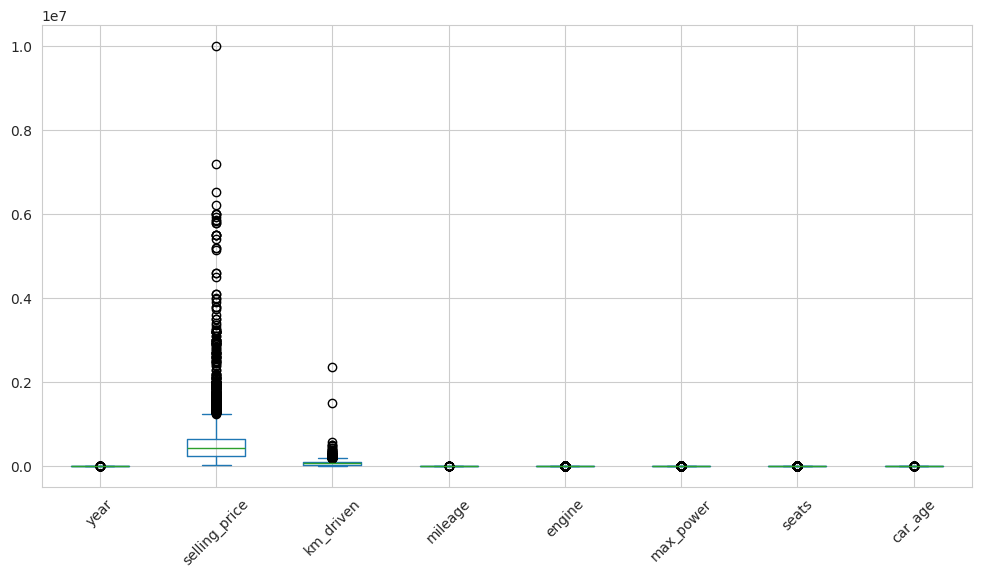

In [57]:
#outlier before
df.select_dtypes(include='number').plot(kind='box',figsize=(12,6),rot=45)
plt.show()

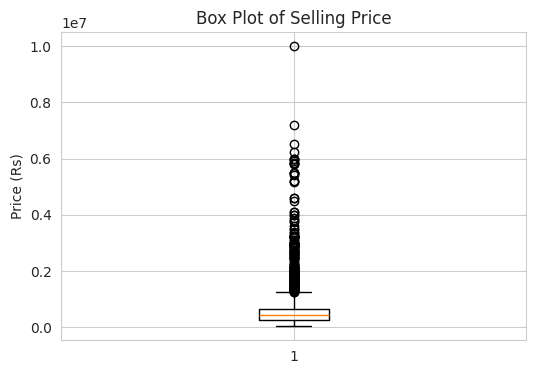

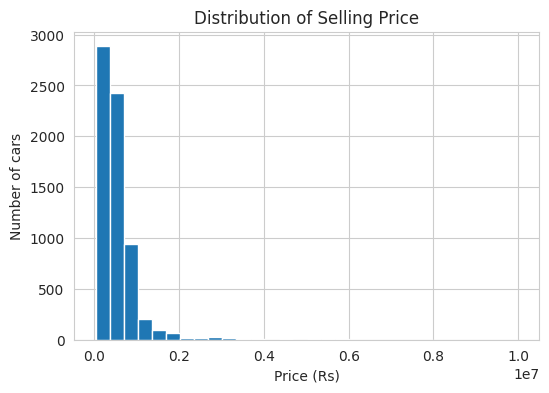

In [58]:
# graph 1: box plot
plt.figure(figsize=(6, 4))
plt.boxplot(df['selling_price'])
plt.title("Box Plot of Selling Price")
plt.ylabel("Price (Rs)")
plt.show()

# graph 2: histogram
plt.figure(figsize=(6, 4))
plt.hist(df['selling_price'], bins=30)
plt.title("Distribution of Selling Price")
plt.xlabel("Price (Rs)")
plt.ylabel("Number of cars")
plt.show()

In [59]:
# removing prize outliers
q1 = df['selling_price'].quantile(0.25)
q3 = df['selling_price'].quantile(0.75)
iqr = q3 - q1
low = q1 - 1.5 * iqr
high = q3 + 1.5 * iqr
df = df[(df['selling_price'] >= low) & (df['selling_price'] <= high)]
print(df.shape)

(6412, 14)


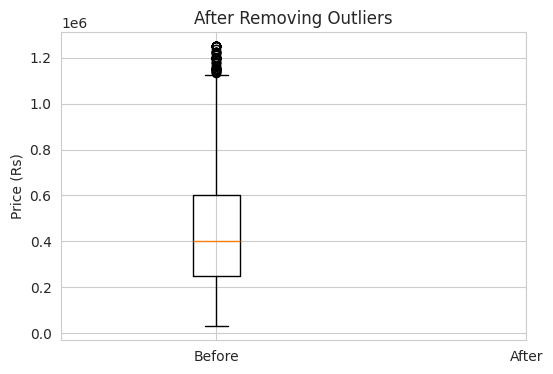

In [60]:
#after removing
plt.figure(figsize=(6, 4))
plt.boxplot(x=df['selling_price'])
plt.xticks([1, 2], ['Before', 'After'])
plt.title("After Removing Outliers")
plt.ylabel("Price (Rs)")
plt.show()

In [61]:
# ---- descriptive statistics ----

# numbers
print(df.describe().round(1))

# categories
print(df.describe(include='object'))

# most common fuel type
print(df['fuel'].value_counts())

# top 5 brands
print(df['brand'].value_counts().head(5))

# average and median price
print("Average price:",round(df['selling_price'].mean()))
print("Median price:",round(df['selling_price'].median()))

         year  selling_price  km_driven  mileage  engine  max_power   seats  \
count  6412.0         6412.0     6412.0   6412.0  6412.0     6411.0  6412.0   
mean   2013.5       443565.9    74654.1     19.7  1391.2       83.9     5.4   
std       3.9       252984.3    59343.3      4.0   459.5       25.7     1.0   
min    1994.0        29999.0        1.0      0.0   624.0       32.8     2.0   
25%    2011.0       250000.0    40000.0     17.0  1196.0       67.1     5.0   
50%    2014.0       400000.0    70000.0     19.7  1248.0       81.8     5.0   
75%    2017.0       600000.0   100000.0     22.5  1498.0       98.6     5.0   
max    2020.0      1250000.0  2360457.0     33.4  3498.0      272.0    14.0   

       car_age  
count   6412.0  
mean       6.5  
std        3.9  
min        0.0  
25%        3.0  
50%        6.0  
75%        9.0  
max       26.0  
                          name    fuel seller_type transmission        owner  \
count                     6412    6412        6412     

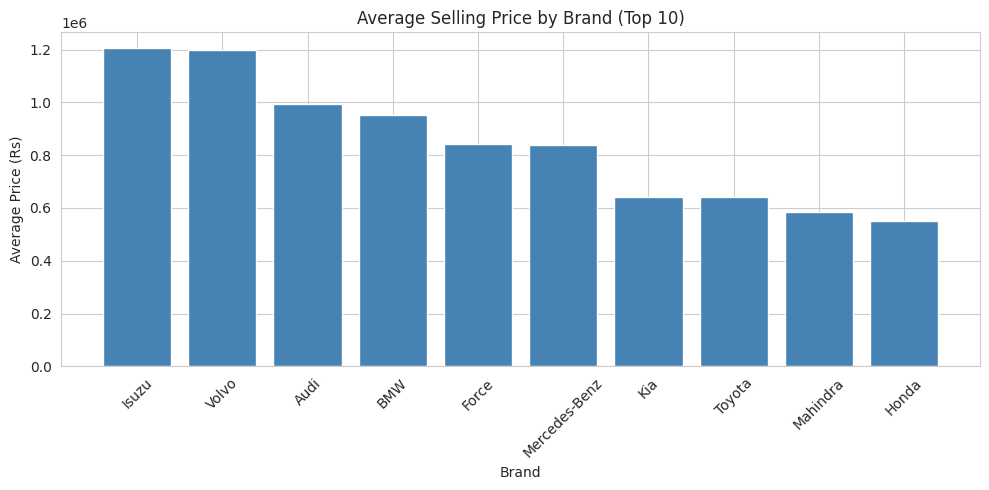

In [62]:
# bar chart - average price by brand (top 10) ----
top = df.groupby('brand')['selling_price'].mean().sort_values(ascending=False).head(10)
plt.figure(figsize=(10, 5))
plt.bar(top.index, top.values, color='steelblue')
plt.title("Average Selling Price by Brand (Top 10)")
plt.xlabel("Brand")
plt.ylabel("Average Price (Rs)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

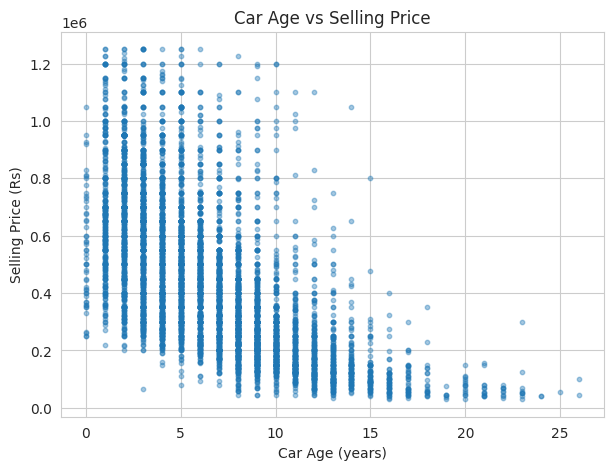

In [63]:
#  scatter - car age vs price ----
plt.figure(figsize=(7, 5))
plt.scatter(df['car_age'], df['selling_price'], s=10, alpha=0.4)
plt.title("Car Age vs Selling Price")
plt.xlabel("Car Age (years)")
plt.ylabel("Selling Price (Rs)")
plt.show()

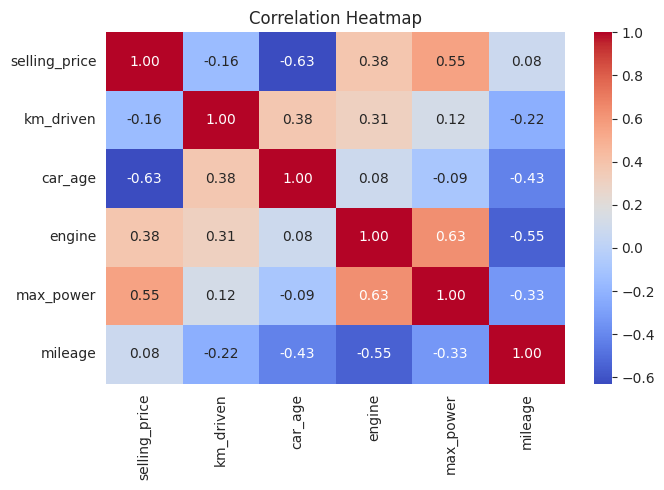

In [64]:
# heatmap - correlation ----
cols = ['selling_price', 'km_driven', 'car_age', 'engine', 'max_power', 'mileage']
plt.figure(figsize=(7, 5))
sns.heatmap(df[cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()